# Klasyfikacja tekstu - metody klasyczneKlasyfikacja opinii z serwisu Yelp (`Yelp/yelp_review_full`) na 5 klas odpowiadających liczbie gwiazdek.Cechy: TF-IDF. Model: MLP w czystym PyTorchu. Monitoring: Weights & Biases.

In [ ]:
!pip install -q datasets
!pip install -q torchmetrics
!pip install -q wandb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 22.5 MB/s eta 0:00:00


In [ ]:
import torch
import torchmetrics
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

print(f"Wersja biblioteki PyTorch: {torch.__version__}")

Wersja biblioteki PyTorch: 2.8.0+cu126


In [ ]:
import osimport wandb# Klucz pobierany ze zmiennej środowiskowej - nie zapisujemy go w notatniku.wandb.login(key=os.environ["WANDB_API_KEY"])

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import torch


class YelpDataLoader():
  def __init__(self, batch_size: int, vocab_size: int, transform_to_lowercase: bool, stop_popular_words: bool, print_logs=True):
    self.batch_size = batch_size
    self.vocab_size = vocab_size
    self.transform_to_lowercase = transform_to_lowercase
    self.stop_popular_words = stop_popular_words
    self.print_logs = print_logs

  def get_dataloaders(self, raw_datasets=None):
      raw_datasets = raw_datasets if raw_datasets else YelpDataLoader.load_yelp_dataset()
      train_raw, val_raw, test_raw = raw_datasets["train"], raw_datasets["val"], raw_datasets["test"]

      train_vecs, val_vecs, test_vecs = self._transform_to_tfidf_format(
          train_raw['text'], val_raw['text'], test_raw['text']
      )

      train_ds = self._make_dataset(train_vecs, train_raw['label'])
      val_ds = self._make_dataset(val_vecs, val_raw['label'])
      test_ds = self._make_dataset(test_vecs, test_raw['label'])
      if self.print_logs:
        print("Created pytorch datasets.")

      train_dl = DataLoader(train_ds, batch_size=self.batch_size, shuffle=True, num_workers=0)
      val_dl = DataLoader(val_ds, batch_size=self.batch_size, shuffle=False, num_workers=0)
      test_dl = DataLoader(test_ds, batch_size=self.batch_size, shuffle=False, num_workers=0)

      if self.print_logs:
        print("Created pytorch dataloaders.")
      return {"train": train_dl, "val": val_dl, "test": test_dl}


  @staticmethod
  def load_yelp_dataset():
      dataset = load_dataset("yelp_review_full")
      splitted = dataset["train"].train_test_split(test_size=0.2)

      train = splitted["train"].shuffle().select(range(100000))
      val = splitted["test"].shuffle().select(range(10000))
      test = dataset["test"].shuffle().select(range(10000))

      print("Loaded dataset from yelp.")
      return {"train": train, "val": val, "test": test}


  def _transform_to_tfidf_format(self, train_texts, val_texts, test_texts):
      stop_words = "english" if self.stop_popular_words else None

      vectorizer = TfidfVectorizer(
          max_features=self.vocab_size,
          lowercase=self.transform_to_lowercase,
          analyzer='word',
          ngram_range=(1, 1),
          stop_words=stop_words
      )

      train_tfidf = vectorizer.fit_transform(train_texts)
      val_tfidf = vectorizer.transform(val_texts)
      test_tfidf = vectorizer.transform(test_texts)

      if self.print_logs:
        print("Transformed yelp dataset to tf-idf format.")
      return train_tfidf, val_tfidf, test_tfidf


  def _make_dataset(self, sparse_features, labels):
      dense_features = sparse_features.astype(np.float32).todense()
      dataset = TensorDataset(
          torch.from_numpy(np.array(dense_features)),
          torch.tensor(labels, dtype=torch.int64)
      )
      return dataset

In [ ]:
import torch
import torch.nn as nn

class MLPModel(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int, hidden_layers_num: int, epochs: int, initial_lr: int, hidden_size=64):
        super().__init__()
        self.n_classes = n_classes
        self.epochs = epochs
        self.initial_lr = initial_lr

        layers = []
        layers.append(nn.Linear(vocab_size, hidden_size))
        layers.append(nn.ReLU())
        for _ in range(hidden_layers_num):
            layers.append(nn.Linear(hidden_size, hidden_size))
            layers.append(nn.ReLU())

        self.feature_extractor = nn.Sequential(*layers)
        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(hidden_size, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.classifier(features)
        return logits

    def train_model(self, loaders: dict[DataLoader], use_wandb = False):
      print("Started model training")
      loss_fn = nn.CrossEntropyLoss()
      optimizer = torch.optim.AdamW(self.parameters(), lr=self.initial_lr, weight_decay=1e-5)
      lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.epochs, eta_min=1e-5)

      metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
      metric_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=self.n_classes).to(device)
      total_acc=None

      for epoch_num in range(1, self.epochs+1):

          for phase in ["train", "val"]:
            if phase == "train":
              self.train()
            else:
              self.eval()

            for batch_num, (features, labels) in enumerate(loaders[phase]):
              features, labels = features.to(device), labels.to(device)
              optimizer.zero_grad()

              with torch.set_grad_enabled(phase == "train"):
                logits = self(features)
                _, predictions = torch.max(logits, dim=1)
                loss = loss_fn(logits, labels)

                if phase == "train":
                  loss.backward()
                  optimizer.step()

              metric_loss(loss)
              metric_acc(predictions, labels)

            acc = metric_acc.compute()
            if phase == "val":
              total_acc = acc

            mean_loss = metric_loss.compute()
            current_lr = lr_scheduler.get_last_lr()[0]
            print(f"(Epoch {epoch_num}/[{phase}]) Loss:\t{mean_loss:.3f}   Accuracy: {acc:.3f}   lr: {current_lr}")
            metrics = {
                f"{phase}/loss": mean_loss,
                f"{phase}/accuracy": acc,
                f"{phase}/lr": current_lr,
            }
            if use_wandb:
              wandb.log(metrics, step=epoch_num)

            metric_loss.reset()
            metric_acc.reset()

          lr_scheduler.step()

      return total_acc

## Analiza błędówWyszukanie *k* przykładów testowych, dla których model najbardziej się myli - czyli tych z najniższą wartością logitu prawdziwej klasy - i sprawdzenie, jak rozkładają się ich prawdziwe etykiety.

In [ ]:
VOCAB_SIZE=10000
BATCH_SIZE=256
TRANSFORM_TO_LOWERCASE=True
STOP_POPULAR_WORDS=True

raw_datasets = YelpDataLoader.load_yelp_dataset()
yelpDataLoader = YelpDataLoader(batch_size=BATCH_SIZE, vocab_size=VOCAB_SIZE, transform_to_lowercase=TRANSFORM_TO_LOWERCASE, stop_popular_words=STOP_POPULAR_WORDS)
dataloaders = yelpDataLoader.get_dataloaders(raw_datasets=raw_datasets)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loaded dataset from yelp.
Transformed yelp dataset to tf-idf format.
Created pytorch datasets.
Created pytorch dataloaders.


In [ ]:
EPOCHS=8
LR=1e-4
HIDDEN_LAYERS_NUM=1

model = MLPModel(vocab_size=VOCAB_SIZE, n_classes=5, hidden_layers_num=HIDDEN_LAYERS_NUM, epochs=EPOCHS, initial_lr=LR).to(device)

if os.path.exists('zadanie1-model.pth'):
  model.load_state_dict(torch.load('zadanie1-model.pth'))
else:
  model.train_model(dataloaders, use_wandb=False)
  torch.save(model.state_dict(), 'zadanie1-model.pth')

In [ ]:
def find_k_worst_predictions(dataloader, raw_dataset, k=10):
    model.eval()
    all_true_logits = []
    all_labels = []
    all_predicted_labels = []
    all_texts = []

    with torch.inference_mode():
        for batch_idx, (features, labels) in enumerate(dataloader):
            features, labels = features.to(device), labels.to(device)
            logits = model(features)
            _, pred = torch.max(logits, dim=1)

            true_class_logits = logits[torch.arange(len(labels)), labels].cpu()

            start = batch_idx * BATCH_SIZE
            end = start + len(labels)
            texts = raw_dataset["text"][start:end]

            all_true_logits.extend(true_class_logits.tolist())
            all_labels.extend(labels.cpu().tolist())
            all_texts.extend(texts)
            all_predicted_labels.extend(pred.cpu().tolist())

    all_true_logits = np.array(all_true_logits)
    worst_indices = np.argsort(all_true_logits)[:k]

    labels_for_worst_indices = []
    print(f"{k} worst predictions (model was significantly wrong):\n")
    for index, indice in enumerate(worst_indices):
        labels_for_worst_indices.append(all_predicted_labels[indice]+1)
        print(f"{index+1}) Logit={all_true_logits[indice]:.4f} | Predicted label={all_predicted_labels[indice]+1} | Real label={all_labels[indice]+1}")
        print(f"TEXT: {all_texts[indice]}\n")

    return labels_for_worst_indices

In [ ]:
labels_for_worst_indices = find_k_worst_predictions(dataloaders["test"], raw_datasets["test"], k=10)

10 worst predictions (model was significantly wrong):

1) Logit=-2.8201 | Predicted label=4 | Real label=1
TEXT: 05/18/13\n\nAZ Restaurant dinner #1 started out fair enough:  Received a voicemail from Sarah in the afternoon asking to confirm my reservation for later that evening.  Called to say I was indeed coming, but may arrive earlier and was told I would be accommodated for patio dining.  I checked in around 8:15p amidst a bustling patio setting and was relegated to the bar with a waiting time of around 15 minutes.  While looking through the wine menu, I decided I'd just eat at the bar.  Bartender Matthew was my server and obliged me with tastes of sauvignon and pinot blancs so that I may decide on a glass ($9) to accompany my three-course meal ($40).  After I'd ordered the pinot, and my prix fixe of soft shell crab, sea bass, and lemon curd tartelette, my complimentary cheese puff arrived. http://www.yelp.com/biz_photos/petite-maison-scottsdale?select=gX_2BIP2yqskNyxU9ugNmA#gX_2BI

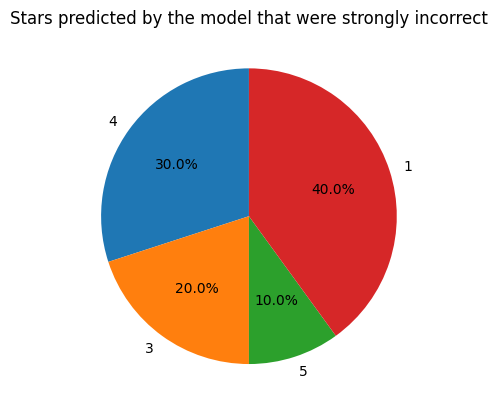

In [ ]:
from collections import Counter

counts = Counter(labels_for_worst_indices)

labels = list(counts.keys())
values = list(counts.values())

plt.pie(values, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title("Stars predicted by the model that were strongly incorrect")
plt.show()

### Wnioski

Po przeanalizowaniu przykładów dla których model najbardziej się mylił, można zauważyć, że błędy powstają gdy:
- treść komentarza jest sprzeczna z daną oceną (na przykład ocena druga),
- treść komentarza zawiera pozytywne/negatywne frazy, ale treść komentarza ma odwrotny wydźwięk.

Najwięcej błędów wynika z tego drugiego powodu. Dzieje się tak ze względu na metodę kodowania tekstu użytą na wejściu klasyfikatora. TF-IDF nie jest w stanie rozpoznać kontekstu i znaczenia słów, liczy jedynie ich częstotliwość, więc model nie rozumie kontekstu emocjonalnego oraz złożonej struktury wypowiedzi.

W szczególności:
- Model nie rozumie złożonej dynamiki opinii - w wielu przypadkach recenzje zaczynają się pozytywnie, zawierają długie opisy jedzenia lub obsługi, a negatywny element pojawia się dopiero na końcu (np. przykład 1: długa pozytywna relacja zakończona mocnym rozczarowaniem przez zachowanie kelnera). TF-IDF traktuje takie recenzje jako pozytywne, bo większość słów ma pozytywne nacechowanie.
- Niepoprawne interpretowanie mieszanych emocji - niektóre recenzje łączą pozytywne i negatywne elementy (np. przykład 3 i 8: chwalony personel, ale krytyka innych aspektów). Model nie potrafi ocenić dominującego tonu wypowiedzi, bo TF-IDF nie rozróżnia relacji pomiędzy zdaniami.
- Problemy z negacją i ironią - np. w przykładzie 5 pojawia się fraza “less than helpful”, która jest negatywna, ale model traktuje słowo “helpful” jako pozytywne, ignorując zaprzeczenie.
- Trudność w rozumieniu emocjonalnych eskalacji i porównań - np. w przykładzie 6 recenzent porównuje restaurację z inną, lepszą, a TF-IDF wychwytuje pozytywne słowa (love, delicious, gourmet), nie rozumiejąc, że służą one do kontrastu i krytyki.

## Wpływ parametrów TF-IDFRozmiar słownika, sprowadzanie do małych liter i odrzucanie najczęstszych słów - każdy parametr zmieniany osobno, porównanie po dokładności na zbiorze walidacyjnym.

In [ ]:
def perform_experiment(results: list, vocab_size, transform_to_lowercase, stop_popular_words):
    print(f"\nEXPERIMENT >>> vocab_size={vocab_size}, lowercase={transform_to_lowercase}, stopwords={stop_popular_words}")

    yelpDataLoader = YelpDataLoader(
        batch_size=BATCH_SIZE,
        vocab_size=vocab_size,
        transform_to_lowercase=transform_to_lowercase,
        stop_popular_words=stop_popular_words
    )

    dataloaders = yelpDataLoader.get_dataloaders(raw_datasets=dataset)
    model = MLPModel(
        vocab_size=vocab_size,
        n_classes=5,
        hidden_layers_num=HIDDEN_LAYERS_NUM,
        epochs=EPOCHS,
        initial_lr=LR
    ).to(device)

    val_acc = model.train_model(dataloaders, use_wandb=False)
    print(val_acc)

    results.append({
        "vocab_size": vocab_size,
        "lowercase": transform_to_lowercase,
        "stopwords": stop_popular_words,
        "val_acc": val_acc
    })

    print("-" * 60)

In [ ]:
EPOCHS = 8
LR = 1e-4
HIDDEN_LAYERS_NUM = 1
BATCH_SIZE = 256

dataset = YelpDataLoader.load_yelp_dataset()

# EKSPERYMENT 1: VOCAB SIZE
vocab_sizes = np.arange(1000, 13001, 4000)
vocab_size_results = []

for vocab_size in vocab_sizes:
    perform_experiment(
        results=vocab_size_results,
        vocab_size=vocab_size,
        transform_to_lowercase=True,
        stop_popular_words=True
    )

vocab_size_results_df = pd.DataFrame(vocab_size_results)
VOCAB_SIZE = int(
    vocab_size_results_df.sort_values(by="val_acc", ascending=False).iloc[0]["vocab_size"]
)

# EKSPERYMENT 2: LOWERCASE
transform_to_lowercase_options = [True, False]
transform_to_lowercase_results = []

for transform_to_lowercase in transform_to_lowercase_options:
    perform_experiment(
        results=transform_to_lowercase_results,
        vocab_size=VOCAB_SIZE,
        transform_to_lowercase=transform_to_lowercase,
        stop_popular_words=True
    )

transform_to_lowercase_results_df = pd.DataFrame(transform_to_lowercase_results)

# EKSPERYMENT 3: STOPWORDS
stop_popular_words_options = [True, False]
stop_popular_words_results = []

for stop_popular_words in stop_popular_words_options:
    perform_experiment(
        results=stop_popular_words_results,
        vocab_size=VOCAB_SIZE,
        transform_to_lowercase=True,
        stop_popular_words=stop_popular_words
    )

stop_popular_words_results_df = pd.DataFrame(stop_popular_words_results)

Loaded dataset from yelp.

EXPERIMENT >>> vocab_size=1000, lowercase=True, stopwords=True
Transformed yelp dataset to tf-idf format.
Created pytorch datasets.
Created pytorch dataloaders.
Started model training
(Epoch 1/[train]) Loss:	1.584   Accuracy: 0.320   lr: 0.0001
(Epoch 1/[val]) Loss:	1.504   Accuracy: 0.449   lr: 0.0001
(Epoch 2/[train]) Loss:	1.354   Accuracy: 0.455   lr: 9.657457896300791e-05
(Epoch 2/[val]) Loss:	1.216   Accuracy: 0.510   lr: 9.657457896300791e-05
(Epoch 3/[train]) Loss:	1.161   Accuracy: 0.512   lr: 8.681980515339464e-05
(Epoch 3/[val]) Loss:	1.102   Accuracy: 0.526   lr: 8.681980515339464e-05
(Epoch 4/[train]) Loss:	1.097   Accuracy: 0.527   lr: 7.222075445642905e-05
(Epoch 4/[val]) Loss:	1.068   Accuracy: 0.535   lr: 7.222075445642905e-05
(Epoch 5/[train]) Loss:	1.076   Accuracy: 0.532   lr: 5.5e-05
(Epoch 5/[val]) Loss:	1.056   Accuracy: 0.536   lr: 5.5e-05
(Epoch 6/[train]) Loss:	1.067   Accuracy: 0.535   lr: 3.777924554357096e-05
(Epoch 6/[val]) Loss:

In [ ]:
for df in [vocab_size_results_df, transform_to_lowercase_results_df, stop_popular_words_results_df]:
    df["val_acc"] = df["val_acc"].apply(lambda x: x.item() if isinstance(x, torch.Tensor) else x)

print("\n=== VOCAB SIZE EXPERIMENT ===")
print(vocab_size_results_df.sort_values(by="val_acc", ascending=False))

print("\n=== TRANSFORM TO LOWERCASE EXPERIMENT ===")
print(transform_to_lowercase_results_df.sort_values(by="val_acc", ascending=False))

print("\n=== STOP POPULAR WORDS EXPERIMENT ===")
print(stop_popular_words_results_df.sort_values(by="val_acc", ascending=False))



=== VOCAB SIZE EXPERIMENT ===
   vocab_size  lowercase  stopwords  val_acc
3       13000       True       True   0.5740
2        9000       True       True   0.5733
1        5000       True       True   0.5664
0        1000       True       True   0.5393

=== TRANSFORM TO LOWERCASE EXPERIMENT ===
   vocab_size  lowercase  stopwords  val_acc
1       13000      False       True   0.5755
0       13000       True       True   0.5625

=== STOP POPULAR WORDS EXPERIMENT ===
   vocab_size  lowercase  stopwords  val_acc
1       13000       True      False   0.5902
0       13000       True       True   0.5763


Wyniki pochodzą jedynie z pojedynczych treningów ze względu na ograniczenia RAM Colabu, długi czas transformowania datasetu na format DF-IDF oraz długi czas treningu.

### Wnioski

VOCAB SIZE:
- Im większa liczba słów w słowniku TF-IDF, tym lepsze accurancy modelu. Tutaj widać najbardziej znaczący wpływ (wzost o 3% skuteczności po zwiększeniu wielkości słownika z 1000 słów do 13000 słów).
- Skok jakości jest szczególnie widoczny przy małych słownikach (1000 → 5000).
- Po 9000–13000 tokenach poprawa jest minimalna, co sugeruje efekt nasycenia: dalsze zwiększanie słownika prawdopodobnie nie przyniesie znaczącego wzrostu dokładności.
- Optymalny vocab_size w tym eksperymencie to 13000.

LOWERCASE

Nie ma większego znaczenia. Różnica w momencie porównania jest na tyle mała, że można ją uznać za przypadkową (zwłaszcza że w poprzednich próbach z lowercase=True wyniki były wyższe).

USUWANIE POPULARNYCH SŁÓW
- Usuwanie popularnych słów (stopwords) w tym zadaniu nieco obniża dokładność. - Najlepszy wynik ze wszystkich uzyskałam z stopwords=False.
- Stopwords w recenzjach mogą zmieniać wydźwięk recenzji (np. "not" w „not good” albo "very" w „very bad”), więc ich usunięcie powoduje utratę ważnej informacji.

## Wpływ hiperparametrów modelu i treninguLiczba warstw ukrytych, liczba epok i początkowa stopa uczenia. Najlepszy model zapisywany i oceniany na zbiorze testowym (raport klasyfikacji + macierz pomyłek).

In [ ]:
EPOCHS=8
LR=1e-4
HIDDEN_LAYERS_NUM=1

VOCAB_SIZE=13000
BATCH_SIZE=256
TRANSFORM_TO_LOWERCASE=True
STOP_POPULAR_WORDS=False

raw_datasets = YelpDataLoader.load_yelp_dataset()
yelpDataLoader = YelpDataLoader(batch_size=BATCH_SIZE, vocab_size=VOCAB_SIZE, transform_to_lowercase=TRANSFORM_TO_LOWERCASE, stop_popular_words=STOP_POPULAR_WORDS)
dataloaders = yelpDataLoader.get_dataloaders(raw_datasets=raw_datasets)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loaded dataset from yelp.
Transformed yelp dataset to tf-idf format.
Created pytorch datasets.
Created pytorch dataloaders.


In [ ]:
def perform_model_params_experiment(the_best_acc, the_best_model, results: list, hidden_layers_num, epochs_num, initial_lr):
    print(f"\nEXPERIMENT >>> hidden_layers_num={hidden_layers_num}, epochs_num={epochs_num}, initial_lr={initial_lr}")

    model = MLPModel(
        vocab_size=VOCAB_SIZE,
        n_classes=5,
        hidden_layers_num=hidden_layers_num,
        epochs=epochs_num,
        initial_lr=initial_lr
    ).to(device)

    val_acc = model.train_model(dataloaders, use_wandb=False)
    print(val_acc)
    if val_acc > the_best_acc:
        the_best_acc = val_acc
        the_best_model = model

    results.append({
        "hidden_layers_num": hidden_layers_num,
        "epochs_num": epochs_num,
        "initial_lr": initial_lr,
        "val_acc": val_acc
    })

    print("-" * 60)
    return the_best_acc, the_best_model

In [ ]:
the_best_model = None
the_best_acc = 0

# EKSPERYMENT 1: HIDDEN LAYERS NUM
hidden_layers_nums = np.arange(1, 10, 2)
hidden_layers_nums_results = []

for hidden_layer_num in hidden_layers_nums:
    the_best_acc, the_best_model = perform_model_params_experiment(
        the_best_acc=the_best_acc,
        the_best_model=the_best_model,
        results=hidden_layers_nums_results,
        hidden_layers_num=hidden_layer_num,
        epochs_num=EPOCHS,
        initial_lr=LR
    )

hidden_layer_num_results_df = pd.DataFrame(hidden_layers_nums_results)
HIDDEN_LAYERS = int(
    hidden_layer_num_results_df.sort_values(by="val_acc", ascending=False).iloc[0]["hidden_layers_num"]
)

# EKSPERYMENT 2: EPOCHS
epochs = np.arange(2, 12, 3)
epochs_results = []

for epoch_num in epochs:
    the_best_acc, the_best_model = perform_model_params_experiment(
        the_best_acc=the_best_acc,
        the_best_model=the_best_model,
        results=epochs_results,
        hidden_layers_num=HIDDEN_LAYERS,
        epochs_num=epoch_num,
        initial_lr=LR
    )

epochs_results_df = pd.DataFrame(epochs_results)
EPOCHS = int(
    epochs_results_df.sort_values(by="val_acc", ascending=False).iloc[0]["epochs_num"]
)


# EKSPERYMENT 3: INITIAL LR
initial_lrs = [0.00001, 0.0001, 0.001, 0.01, 0.1, 0.3]
initial_lrs_results = []

for initial_lr in initial_lrs:
    the_best_acc, the_best_model = perform_model_params_experiment(
        the_best_acc=the_best_acc,
        the_best_model=the_best_model,
        results=initial_lrs_results,
        hidden_layers_num=HIDDEN_LAYERS,
        epochs_num=EPOCHS,
        initial_lr=initial_lr
    )

initial_lrs_results_df = pd.DataFrame(initial_lrs_results)


EXPERIMENT >>> hidden_layers_num=1, epochs_num=8, initial_lr=0.0001
Started model training
(Epoch 1/[train]) Loss:	1.561   Accuracy: 0.356   lr: 0.0001
(Epoch 1/[val]) Loss:	1.441   Accuracy: 0.499   lr: 0.0001
(Epoch 2/[train]) Loss:	1.280   Accuracy: 0.504   lr: 9.657457896300791e-05
(Epoch 2/[val]) Loss:	1.153   Accuracy: 0.543   lr: 9.657457896300791e-05
(Epoch 3/[train]) Loss:	1.076   Accuracy: 0.558   lr: 8.681980515339464e-05
(Epoch 3/[val]) Loss:	1.030   Accuracy: 0.564   lr: 8.681980515339464e-05
(Epoch 4/[train]) Loss:	0.986   Accuracy: 0.579   lr: 7.222075445642905e-05
(Epoch 4/[val]) Loss:	0.983   Accuracy: 0.572   lr: 7.222075445642905e-05
(Epoch 5/[train]) Loss:	0.946   Accuracy: 0.593   lr: 5.5e-05
(Epoch 5/[val]) Loss:	0.963   Accuracy: 0.575   lr: 5.5e-05
(Epoch 6/[train]) Loss:	0.926   Accuracy: 0.599   lr: 3.777924554357096e-05
(Epoch 6/[val]) Loss:	0.954   Accuracy: 0.580   lr: 3.777924554357096e-05
(Epoch 7/[train]) Loss:	0.915   Accuracy: 0.604   lr: 2.3180194846

In [ ]:
torch.save(the_best_model.state_dict(), 'zadanie3-najlepszy-model.pth')

In [ ]:
for df in [hidden_layer_num_results_df, epochs_results_df, initial_lrs_results_df]:
    df["val_acc"] = df["val_acc"].apply(lambda x: x.item() if isinstance(x, torch.Tensor) else x)

print("\n=== HIDDEN LAYERS EXPERIMENT ===")
print(hidden_layer_num_results_df.sort_values(by="val_acc", ascending=False))

print("\n=== EPOCHS EXPERIMENT ===")
print(epochs_results_df.sort_values(by="val_acc", ascending=False))

print("\n=== INITIAL LEARNING RATE EXPERIMENT ===")
print(initial_lrs_results_df.sort_values(by="val_acc", ascending=False))



=== HIDDEN LAYERS EXPERIMENT ===
   hidden_layers_num  epochs_num  initial_lr  val_acc
1                  3           8      0.0001   0.5874
0                  1           8      0.0001   0.5823
4                  9           8      0.0001   0.5581
3                  7           8      0.0001   0.5474
2                  5           8      0.0001   0.5437

=== EPOCHS EXPERIMENT ===
   hidden_layers_num  epochs_num  initial_lr  val_acc
1                  3           5      0.0001   0.5871
3                  3          11      0.0001   0.5773
2                  3           8      0.0001   0.5428
0                  3           2      0.0001   0.4974

=== INITIAL LEARNING RATE EXPERIMENT ===
   hidden_layers_num  epochs_num  initial_lr  val_acc
2                  3           5     0.00100   0.5717
4                  3           5     0.10000   0.5549
3                  3           5     0.01000   0.5374
1                  3           5     0.00010   0.5293
0                  3           5 

In [ ]:
preds = []
labels = []

the_best_model.eval()

for index, (X_batch, Y_batch) in enumerate(dataloaders["test"]):
  X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)

  with torch.inference_mode():
    logits = the_best_model(X_batch)
    _, batch_preds = torch.max(logits, dim=1)
    preds.extend(batch_preds.cpu().numpy())
    labels.extend(Y_batch.cpu().numpy())

preds = np.array(preds)
targets = np.array(labels)

In [ ]:
from sklearn.metrics import classification_report

labels = ['1 gwiazdka', '2 gwiazdki', '3 gwiazdki', '4 gwiazdki', '5 gwiazdek']

report = classification_report(targets, preds, target_names = labels)
print(report)

              precision    recall  f1-score   support

  1 gwiazdka       0.70      0.74      0.72      1977
  2 gwiazdki       0.51      0.52      0.52      2027
  3 gwiazdki       0.49      0.46      0.47      1987
  4 gwiazdki       0.50      0.48      0.49      1984
  5 gwiazdek       0.69      0.71      0.70      2025

    accuracy                           0.58     10000
   macro avg       0.58      0.58      0.58     10000
weighted avg       0.58      0.58      0.58     10000



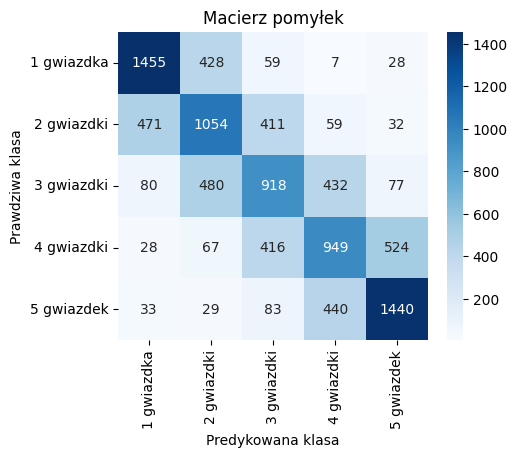

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(targets, preds)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Macierz pomyłek')
plt.xlabel('Predykowana klasa')
plt.ylabel('Prawdziwa klasa')
plt.show()


### Wnioski

HIDDEN LAYERS:
- Najlepsze wyniki model osiąga dla mniejszej ilości warstw ukrytych (porównywalnie dobrze ~58% dla 1-3 warstw ukrytych).
- Wraz ze wzrostem liczb warstw ukrytych, spada skuteczność modelu. Zbyt wiele warstw prawdopodobnie prowadzi do utraty informacji (gradient vanishing) i lekkiego przeuczenia sieci (dla większej ilości ukrytych warstw skuteczność na zbiorze treningowym wzrosła w stosunku do skuteczności na zbiorze walidacyjnym).

EPOCHS
- Najlepszy wyniki model uzyskuje przy 5-11 epokach (wcześniej 8 epok osiągało porównywalnie dobre wyniki, val_acc = ~0.58).
- 2 epoki to zbyt krótki trening - model nie zdążył się wystarczająco dopasować.
- Dalsze zwiększanie liczby epok będzie prowadzić do przeuczenia i zmniejszenia skuteczności.

INITIAL LEARNING RATE
- Najlepsze wyniki osiągnięto przy learning rate = 0.001 (val_acc = 0.5717).
- Zbyt niski LR (0.00001) skutkuje bardzo słabym uczeniem - model praktycznie nie zbiega.
- Zbyt wysoki LR (>0.01) powoduje niestabilne uczenie i spadek dokładności. Widać też znaczące przeuczenie (ogromne różnice między zbiorem walidacyjnym a treningowym).

OSTATECZNA EWALUACJA
- Model najlepiej rozpoznaje ekstremalne klasy (1 i 5 gwiazdek), co widać po wysokich wynikach F1 (~0.7).
- Klasy środkowe (2–4 gwiazdki) są trudniejsze - często mylone między sobą, co potwierdza macierz pomyłek.
- Błędy są głównie sąsiednie (np. 3↔4 gwiazdki), co sugeruje, że model rozumie gradację ocen, ale nie ma wyraźnych granic między nimi.


## Eksploracja zbioru i reprezentacji TF-IDF

#### Pobranie i analiza dataset'u

In [ ]:
from datasets import load_dataset

dataset = load_dataset("Yelp/yelp_review_full")
splitted_dataset = dataset["train"].train_test_split(test_size=0.2)

train_dataset = splitted_dataset["train"].shuffle().select(range(100000))
val_dataset = splitted_dataset["test"].shuffle().select(range(10000))
test_dataset = dataset["test"].shuffle().select(range(10000))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…):   0%|          | 0.00/299M [00:00<?, ?B/s]

yelp_review_full/test-00000-of-00001.par(…):   0%|          | 0.00/23.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

# WIELKOŚĆ ZBIORU
Liczba próbek w zbiorze treningowym: 100000
Liczba próbek w zbiorze walidacyjnym: 10000
Liczba próbek w zbiorze testowym: 10000


# EXAMPLE ELEMENT OF DATASET
Etykieta: 1
Treść opinii: Went here tonight. I bought an ocean blue goblet. It was decent definitely not worth the $36 dollars. Decent place, just extremely pricey.


# LABEL DISTRIBUTION


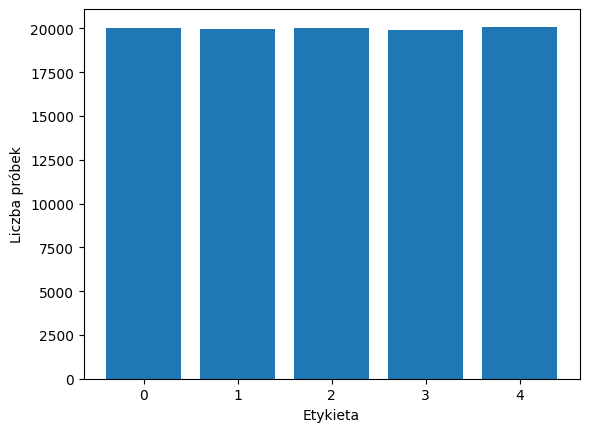

In [ ]:
print("# WIELKOŚĆ ZBIORU")
print(f"Liczba próbek w zbiorze treningowym: {len(train_dataset)}")
print(f"Liczba próbek w zbiorze walidacyjnym: {len(val_dataset)}")
print(f"Liczba próbek w zbiorze testowym: {len(test_dataset)}")

print("\n")

example_sample = train_dataset[0]
print("# EXAMPLE ELEMENT OF DATASET")
print(f"Etykieta: {example_sample['label']}")
print(f"Treść opinii: {example_sample['text']}")

print("\n")

unique_labels, count = np.unique(train_dataset['label'], return_counts=True)
print("# LABEL DISTRIBUTION")
plt.bar(unique_labels, count)
plt.xlabel("Etykieta")
plt.ylabel("Liczba próbek")
plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vocab_size = 1000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    lowercase=True,
    analyzer='word',
    ngram_range=(1, 1),
    stop_words="english"
)

train_tfidf_vectors = vectorizer.fit_transform(train_dataset['text'])
validate_tfidf_vectors = vectorizer.transform(val_dataset['text'])
test_tfidf_vectors = vectorizer.transform(test_dataset['text'])


# EXAMPLE TF-IDF VECTOR
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 12 stored elements and shape (1, 1000)>
  Coords	Values
  (0, 968)	0.17987584416714403
  (0, 897)	0.3440735951116455
  (0, 86)	0.312212309607598
  (0, 82)	0.3385521351518005
  (0, 207)	0.48251405795541746
  (0, 211)	0.20632916431360926
  (0, 987)	0.223461979013087
  (0, 239)	0.33133520394470756
  (0, 643)	0.12112810462794363
  (0, 432)	0.1331025863050666
  (0, 285)	0.2757180359758849
  (0, 671)	0.30601536262582263


# FEATURE NAMES
['eye' 'spinach' 'expecting' 'staff' 'website' 'know' 'rolls' 'didn'
 'wonderful' 'best' 'money' 'ended' 'noodles' 'beef' 'given' 'seafood'
 'star' 'pho' 'past' 'heat']


# WORDS IN VECTOR


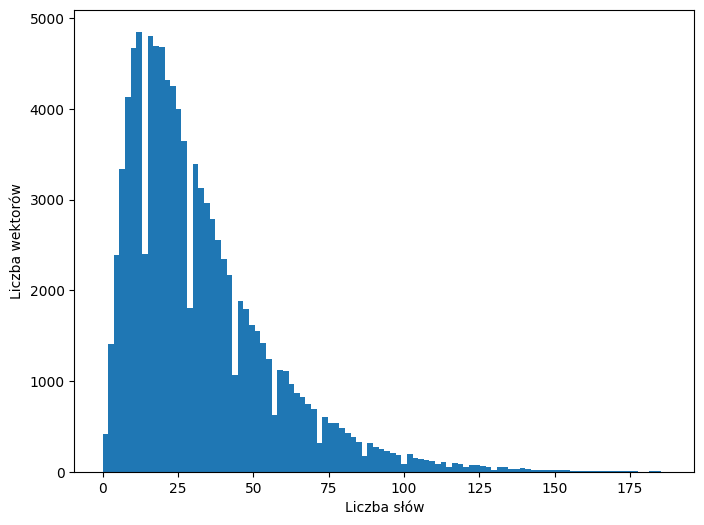

In [ ]:
print("# EXAMPLE TF-IDF VECTOR")
print(train_tfidf_vectors[0])

print("\n")

print("# FEATURE NAMES")
feature_names = vectorizer.get_feature_names_out()
print(np.random.choice(feature_names, 20))

print("\n")

print("# WORDS IN VECTOR")
words_in_vectors = np.diff(train_tfidf_vectors.indptr)
plt.figure(figsize=(8, 6))
plt.hist(words_in_vectors, bins=100)
plt.xlabel("Liczba słów")
plt.ylabel("Liczba wektorów")
plt.show()

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

def make_dataset(tfidf_vectors, labels):
  dense_features = tfidf_vectors.astype(np.float32).todense()
  dataset = TensorDataset(torch.from_numpy(dense_features), torch.tensor(labels))
  return dataset

train_dataset = make_dataset(train_tfidf_vectors, train_dataset['label'])
validation_dataset = make_dataset(validate_tfidf_vectors, val_dataset['label'])
test_dataset = make_dataset(test_tfidf_vectors, test_dataset['label'])

Train dataset: (tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.3386, 0.0000, 0.0000, 0.0000, 0.3122, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 

In [ ]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
validation_dataloader = DataLoader(validation_dataset, batch_size=32, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)